**Generate and Document Multidimensional Data**

Dataset shape: (2000, 10)
Each row is one sample; each column is one feature.
Feature 1: Mean = 0, Variance = 1
Feature 2: Mean = 1, Variance = 2
Feature 3: Mean = 2, Variance = 3
Feature 4: Mean = 3, Variance = 4
Feature 5: Mean = 4, Variance = 5
Feature 6: Mean = 5, Variance = 6
Feature 7: Mean = 6, Variance = 7
Feature 8: Mean = 7, Variance = 8
Feature 9: Mean = 8, Variance = 9
Feature 10: Mean = 9, Variance = 10


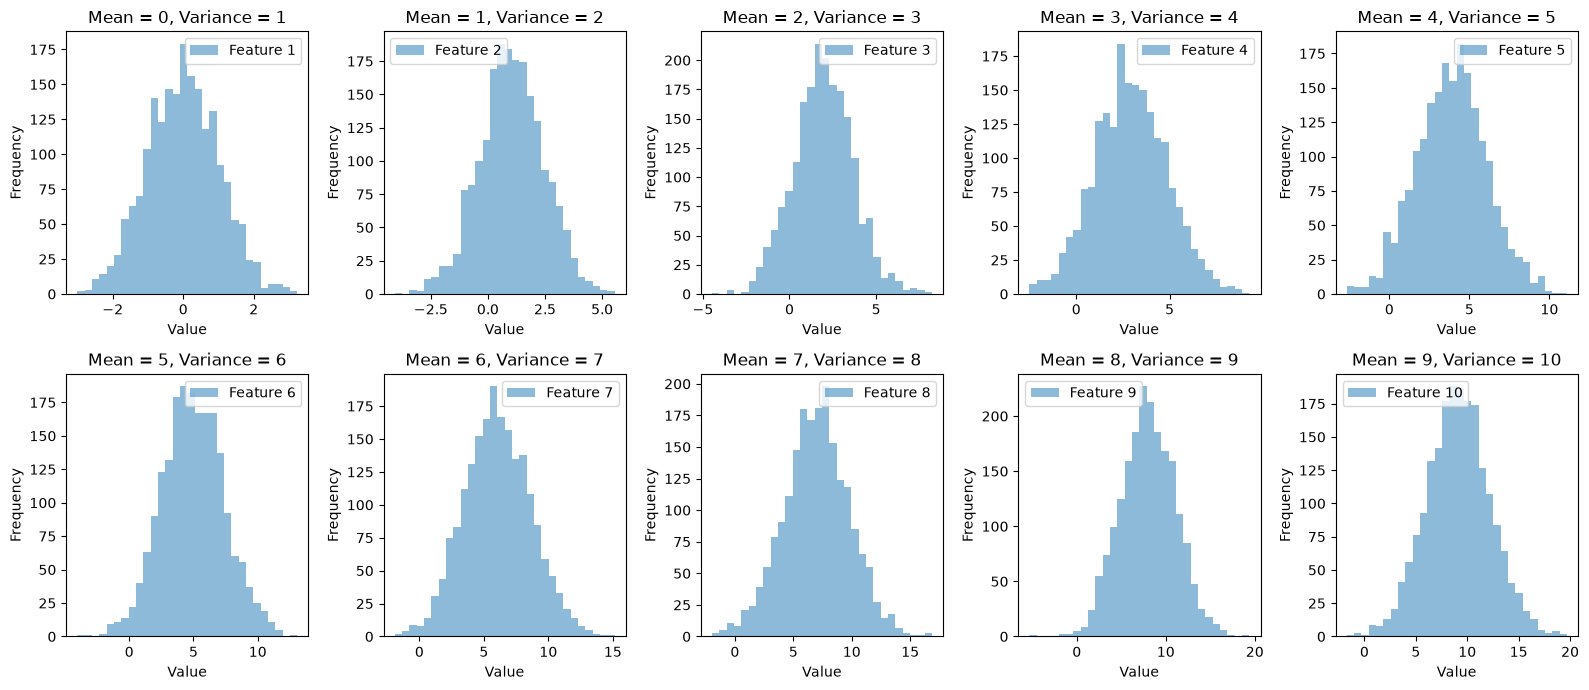

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Generate multidimensional data
np.random.seed(0)

n_samples = 2000
n_features = 10

# Each feature has a different mean and variance
means = np.arange(n_features)          # Means: 0, 1, ..., 9
variances = np.arange(1, n_features + 1)  # Variances: 1, 2, ..., 10

# NumPy's scale parameter uses standard deviation
standard_deviations = np.sqrt(variances)

data = np.random.normal(
    loc=means,
    scale=standard_deviations,
    size=(n_samples, n_features)
)

# Document the dataset
print("Dataset shape:", data.shape)
print("Each row is one sample; each column is one feature.")

for i in range(n_features):
    print(
        f"Feature {i + 1}: "
        f"Mean = {means[i]}, Variance = {variances[i]}"
    )

# Plot the distribution of each feature
fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for i, ax in enumerate(axes.flat):
    ax.hist(data[:, i], bins=30, alpha=0.5, label=f'Feature {i + 1}')
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')
    ax.set_title(f'Mean = {means[i]}, Variance = {variances[i]}')
    ax.legend()

plt.tight_layout()
plt.show()

**Introduce Complex Shifts**

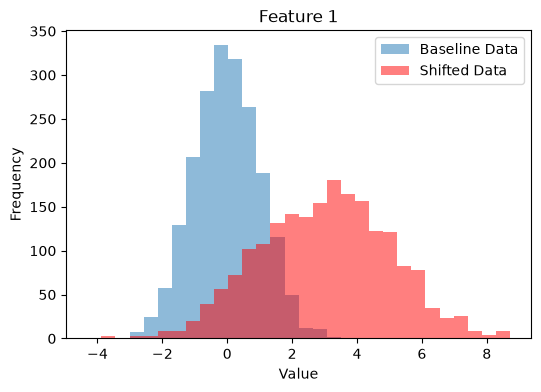

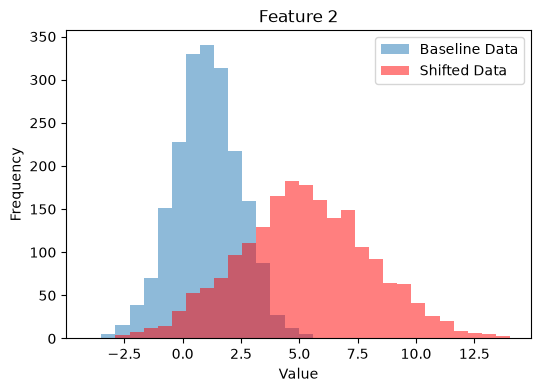

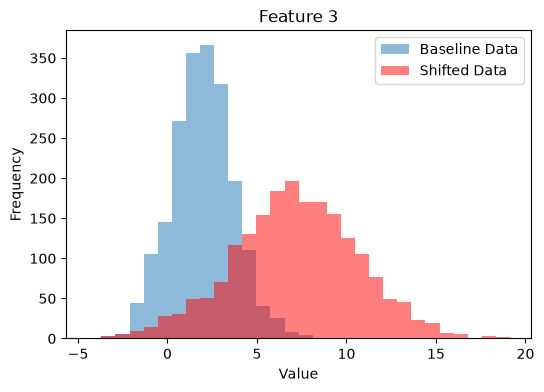

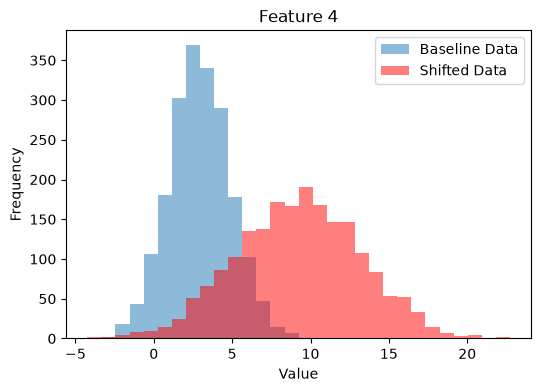

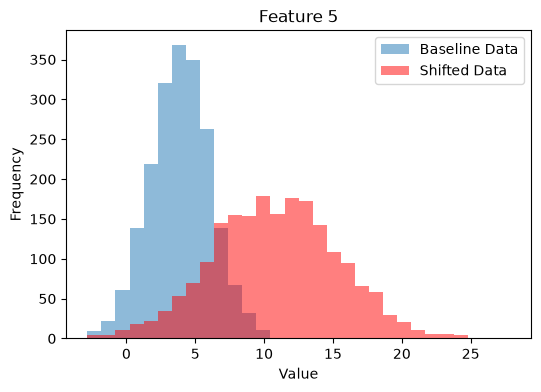

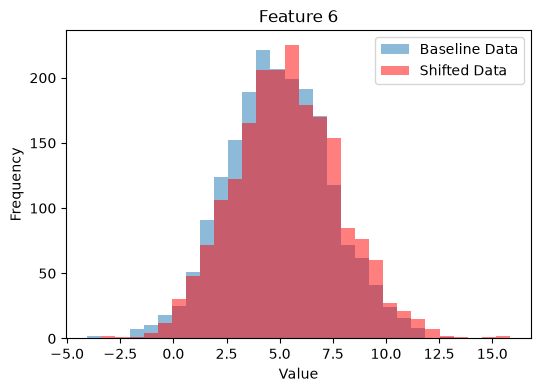

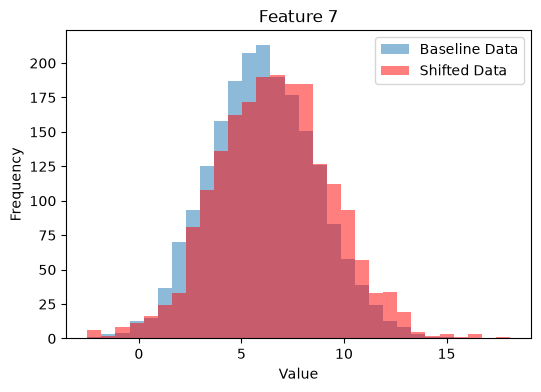

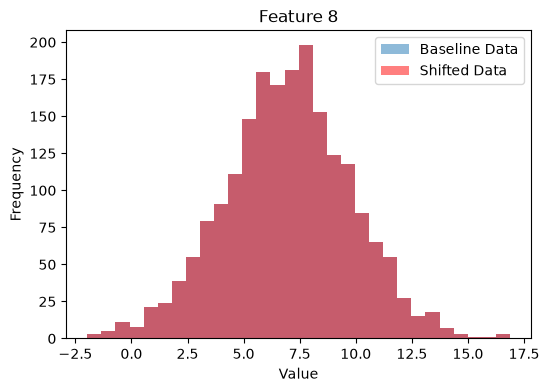

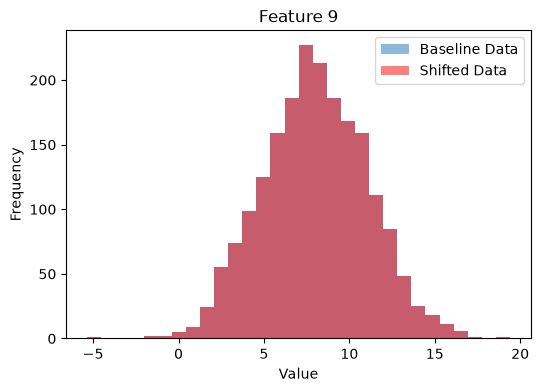

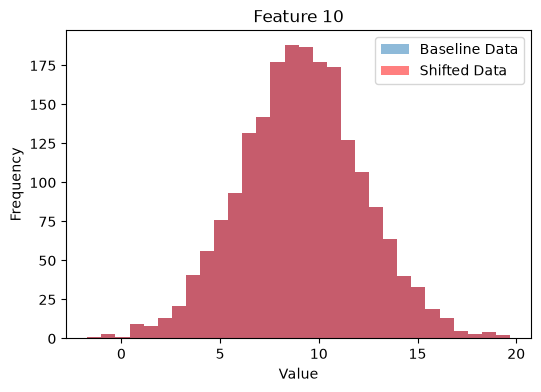

In [2]:
# Set shifted means and variances
shifted_means = means.astype(float).copy()
shifted_variances = variances.astype(float).copy()

# Significant shifts in five features
shifted_means[:5] += 3 * standard_deviations[:5]
shifted_variances[:5] *= 4

# Subtle shifts in two other features
shifted_means[5:7] += 0.2 * standard_deviations[5:7]
shifted_variances[5:7] *= 1.10

# Generate shifted data
np.random.seed(1)
shifted_data = np.random.normal(
    loc=shifted_means,
    scale=np.sqrt(shifted_variances),
    size=(2000, 10)
)

# Keep the remaining three features unchanged
shifted_data[:, 7:] = data[:, 7:]

# Plot both distributions for each feature
for i in range(10):
    plt.figure(figsize=(6, 4))

    # Use the same bins for both distributions
    bins = np.histogram_bin_edges(
        np.concatenate([data[:, i], shifted_data[:, i]]),
        bins=30
    )

    plt.hist(data[:, i], bins=bins, alpha=0.5, label='Baseline Data')
    plt.hist(
        shifted_data[:, i], bins=bins, alpha=0.5,
        label='Shifted Data', color='r'
    )
    plt.title(f'Feature {i + 1}')
    plt.xlabel('Value')
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()

**Advanced Visualization Techniques**

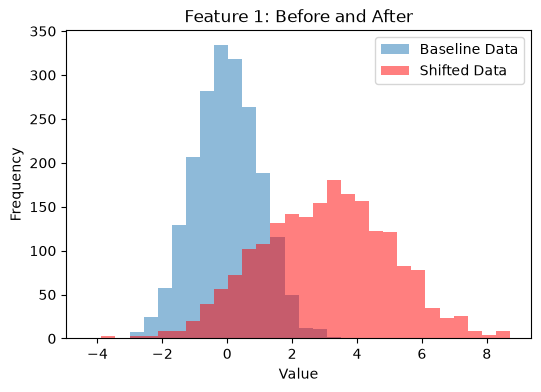

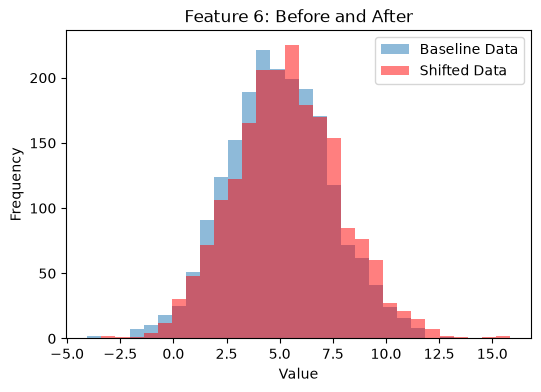

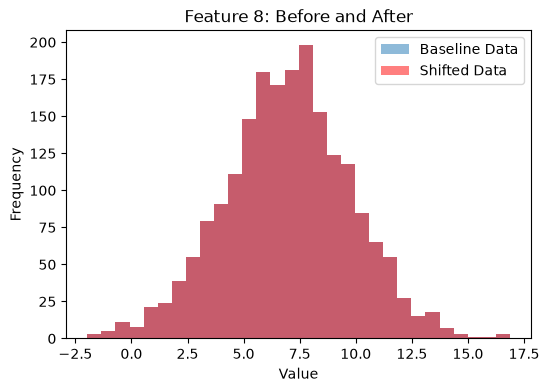

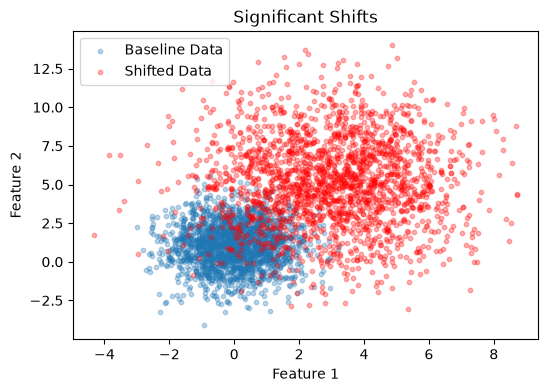

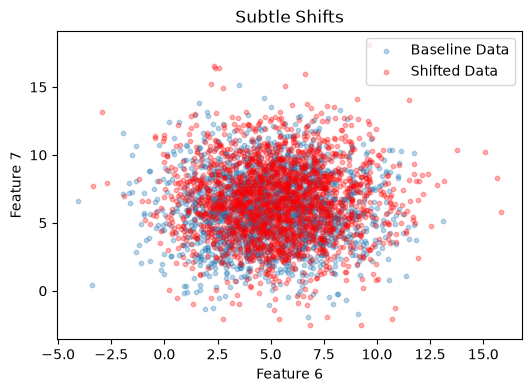

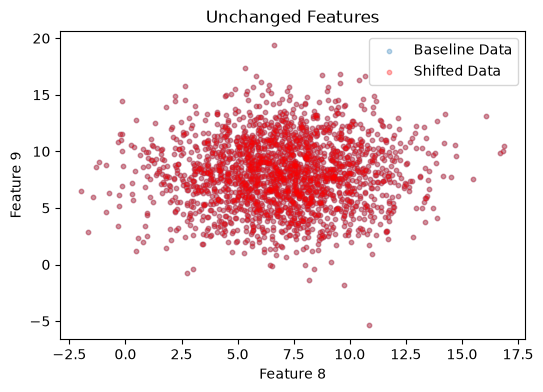

In [3]:
# Plot histograms for selected features
# Feature 1: significant shift
# Feature 6: subtle shift
# Feature 8: unchanged
selected_features = [0, 5, 7]

for i in selected_features:
    plt.figure(figsize=(6, 4))

    # Use the same bins for baseline and shifted data
    bins = np.histogram_bin_edges(
        np.concatenate([data[:, i], shifted_data[:, i]]),
        bins=30
    )

    plt.hist(data[:, i], bins=bins, alpha=0.5, label='Baseline Data')
    plt.hist(
        shifted_data[:, i], bins=bins, alpha=0.5,
        label='Shifted Data', color='r'
    )

    plt.title(f'Feature {i + 1}: Before and After')
    plt.xlabel('Value')
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()

# Plot scatter plots for selected feature pairs
feature_pairs = [
    (0, 1, 'Significant Shifts'),
    (5, 6, 'Subtle Shifts'),
    (7, 8, 'Unchanged Features')
]

for x, y, title in feature_pairs:
    plt.figure(figsize=(6, 4))

    plt.scatter(
        data[:, x], data[:, y],
        alpha=0.3, s=10, label='Baseline Data'
    )
    plt.scatter(
        shifted_data[:, x], shifted_data[:, y],
        alpha=0.3, s=10, label='Shifted Data', color='r'
    )

    plt.title(title)
    plt.xlabel(f'Feature {x + 1}')
    plt.ylabel(f'Feature {y + 1}')
    plt.legend()
    plt.show()

In [ ]:
**Statistical Detection of Shifts**

In [6]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 2.5 MB/s eta 0:00:05
   --- ------------------------------------ 1.0/11.3 MB 2.4 MB/s eta 0:00:05
   -------- ------------------------------- 2.4/11.3 MB 3.9 MB/s eta 0:00:03
   ------------- -------------------------- 3.9/11.3 MB 5.1 MB/s eta 0:00:02
   ----------------- ---------------------- 5.0/11.3 MB 5.3 MB/s eta 0:00:02
   ------------------------ --------------- 7.1/11.3 MB 5.6 MB/s eta 0:00:01
   ---------------------------- ----------- 8.1/11.3 MB 5.5 MB/s eta 0:00:01
   -------------------------------- ------- 9.2/11.3 MB 5.5 MB/s eta 0:00:01
   ------------------------------------ --- 10.5/11.3 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 5.4 MB/s  0:00:02

   -------- ------------------------------- 1/5 [patsy]
   ---------------- --------------

In [10]:
import pandas as pd
from scipy.stats import ks_2samp, anderson_ksamp, levene
from statsmodels.stats.multitest import multipletests
from scipy.stats import PermutationMethod

results = []

for i in range(n_features):
    baseline = data[:, i]
    shifted = shifted_data[:, i]

    # Detect differences in the overall distributions
    ks_result = ks_2samp(baseline, shifted)

    # Identical features were copied, so no test is needed
    if np.array_equal(baseline, shifted):
        ad_statistic = np.nan
        ad_pvalue = 1.0
    else:
        ad_result = anderson_ksamp(
            [baseline, shifted],
            variant='continuous',
            method=PermutationMethod(
                n_resamples=9999,
                rng=np.random.default_rng(42)
    )
)
        ad_statistic = ad_result.statistic
        ad_pvalue = ad_result.pvalue

    # Detect differences in variance
    levene_result = levene(baseline, shifted, center='median')

    results.append({
        'Feature': f'Feature {i + 1}',
        'KS statistic': ks_result.statistic,
        'KS p-value': ks_result.pvalue,
        'AD statistic': ad_statistic,
        'AD p-value': ad_pvalue,
        'Levene p-value': levene_result.pvalue
    })

results_df = pd.DataFrame(results)

# Holm correction across all 30 tests
pvalue_columns = ['KS p-value', 'AD p-value', 'Levene p-value']
all_pvalues = results_df[pvalue_columns].to_numpy().ravel()

adjusted_pvalues = multipletests(
    all_pvalues,
    alpha=0.05,
    method='holm'
)[1].reshape(n_features, 3)

for j, test in enumerate(['KS', 'AD', 'Levene']):
    results_df[f'{test} adjusted p-value'] = adjusted_pvalues[:, j]
    results_df[f'{test} detects shift'] = adjusted_pvalues[:, j] < 0.05

print(results_df.round(4).to_string(index=False))

   Feature  KS statistic  KS p-value  AD statistic  AD p-value  Levene p-value  KS adjusted p-value  KS detects shift  AD adjusted p-value  AD detects shift  Levene adjusted p-value  Levene detects shift
 Feature 1        0.6980      0.0000     1328.8265      0.0001           0.000               0.0000              True               0.0019              True                   0.0000                  True
 Feature 2        0.7055      0.0000     1324.7646      0.0001           0.000               0.0000              True               0.0019              True                   0.0000                  True
 Feature 3        0.7230      0.0000     1355.2837      0.0001           0.000               0.0000              True               0.0019              True                   0.0000                  True
 Feature 4        0.7325      0.0000     1431.5149      0.0001           0.000               0.0000              True               0.0019              True                   0.0000   

P-values displayed as 0.0000 are extremely small
features 1-5 shows Strong evidence of distribution and variance changes. Large KS statistics (0.698–0.733) support substantial shifts.
feature 6 Tshows there is insufficient evidence of a variance change.
feature 7 shows the distribution and variance changes are detectable, despite the shift being subtle.

Recommendation
Monitor distributions regularly: Track feature means, variances, KS statistics, and adjusted p-values. Prioritize Features 1–5 because their shifts are largest.
Investigate the cause: Check for measurement changes, data processing errors, or changes in the population.
Evaluate with recent labelled data: Compare the model’s performance before and after the shift using suitable metrics, such as macro F1 for classification or RMSE for regression